# 02 · Results: can the model tell factual from creative text?

Reads what notebook 01 saved (no model run). For every **signal** (24 of them, listed in section 2) each text
becomes a **curve**: the signal's value at each word or token, in reading order. The curves are sorted into two
groups with 12 **setups** (`analysis/classify.py`) and every signal is judged by four tests
(`analysis/robustness.py`):

1. **strong**: the best setup sorts at least 90% of the texts into their own kind's group
2. **beats chance**: random shuffles of the kinds reach that score less than 1% of the time
3. **leave one out**: with any single text left out, the best setup still reaches 90%
4. **DTW window**: with DTW windows of 5%, 10% and 20%, the best setup still reaches 90%

A signal that passes all four is a **robust result**. Everything is saved to `results/tables/` and
`results/figures/`; the write-up is `CONCLUSIONS.md`. Settings are in `config.py`.

**Runtime:** about 15 minutes (section 3).

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))            # run from the Qwen7B folder: makes config and analysis importable

import analysis                                # also makes lca_core (repo root) importable
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from analysis.classify import group, setup_from_name
from analysis.figures import (plot_curves, plot_leave_one_out, plot_memorisation, plot_overview, plot_setups,
                              save)
from analysis.robustness import judge
from analysis.signals import SIGNALS, curves_of, dataset_names, kinds_of, load_tables
from config import EXCLUDED_TEXTS, MEMORISATION_FILE, MEMORISATION_THRESHOLD, MODEL_NAME, TABLES_DIR

TABLES_DIR.mkdir(parents=True, exist_ok=True)
names = dataset_names()
kinds = kinds_of(names)
word_tables, token_tables = load_tables(names, MODEL_NAME)
print(f"{len(names)} texts: {(kinds == 'factual').sum()} factual, {(kinds == 'creative').sum()} creative")

25 texts: 12 factual, 13 creative


## 1. Dataset: which texts are used
The memorisation test (notebook 01, `analysis/memorisation.py`): the model gets 100 tokens of the real text and
writes the next 50 by itself; the score is the share it gets exactly right, averaged over 5 passages. Texts at or
above the threshold would be left out; none reach it, so all 25 texts are used (`docs/adr/0002`). Texts can also
be left out by name with `EXCLUDED_TEXTS` in `config.py` (currently none).

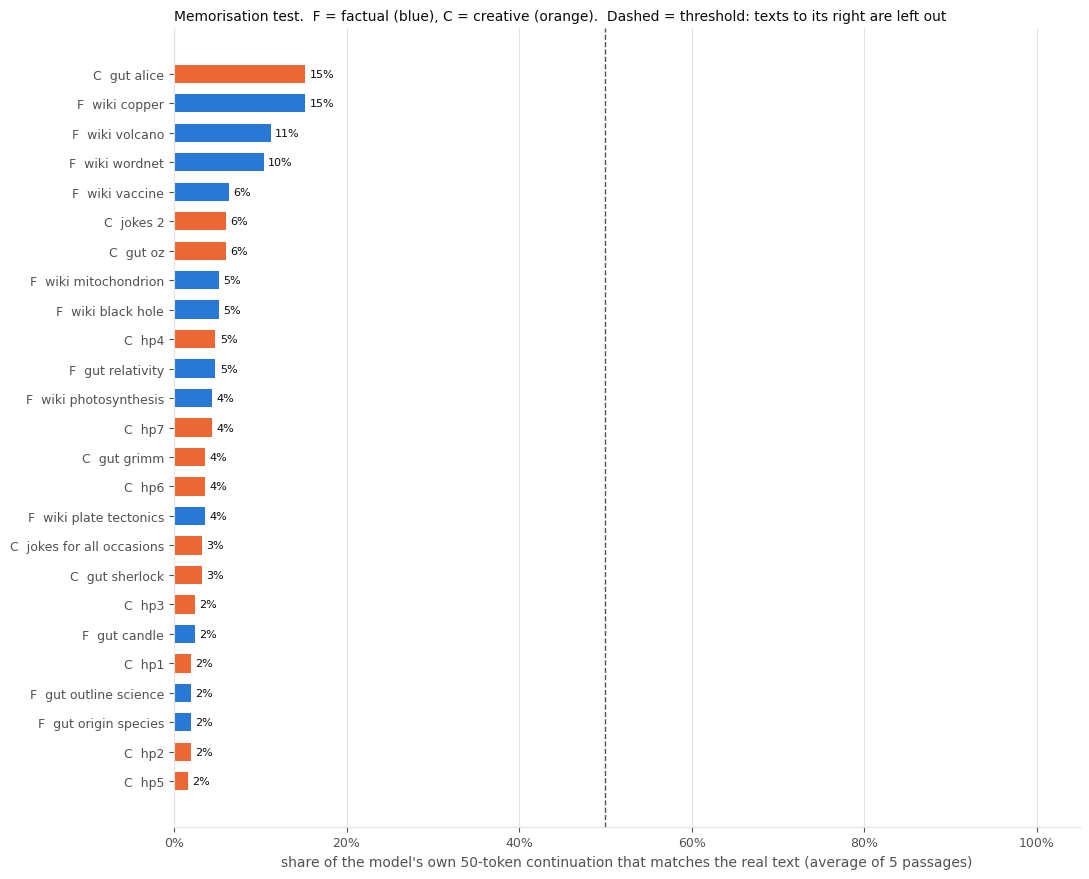

left out by decision: {}


,text,match score,best passage,memorised
0,creative_gut_alice,0.15,0.42,False
1,factual_wiki_copper,0.15,0.38,False
2,factual_wiki_volcano,0.11,0.48,False
3,factual_wiki_wordnet,0.10,0.30,False
4,factual_wiki_vaccine,0.06,0.12,False
5,creative_gut_oz,0.06,0.16,False
6,creative_jokes_2,0.06,0.16,False
7,factual_wiki_black_hole,0.05,0.12,False
8,factual_wiki_mitochondrion,0.05,0.16,False
9,creative_hp4,0.05,0.12,False


In [2]:
memorisation = pd.read_csv(MEMORISATION_FILE)
save(plot_memorisation(memorisation, MEMORISATION_THRESHOLD), "1_memorisation.png")
plt.show()
print("left out by decision:", EXCLUDED_TEXTS)
memorisation[["text", "match score", "best passage", "memorised"]].round(2)

## 2. The signals
Every signal is computed for every text and goes through the same classification and tests.
How each value is calculated is explained in `CONCLUSIONS.md` and in `analysis/signals.py`.

In [3]:
signal_rows = []
for signal in SIGNALS:
    signal_rows.append({"signal": signal.key, "name": signal.name, "family": signal.family,
                        "one value per": signal.time_axis, "how": signal.how})
pd.set_option("display.max_colwidth", 140)
pd.DataFrame(signal_rows)

,signal,name,family,one value per,how
0,lca_top1,"LCA height, top 1 vs real word",guess meaning,word,"WordNet levels climbed until the words share a category (0 = same word), between the model's #1 guess and the word that really came"
1,lca_top3,"LCA height, top 3 guesses",guess meaning,word,"WordNet levels climbed until the words share a category (0 = same word), between the model's 3 best guesses"
2,lca_top5,"LCA height, top 5 guesses",guess meaning,word,"WordNet levels climbed until the words share a category (0 = same word), between the model's 5 best guesses"
3,lca_likely,"LCA height, likely guesses",guess meaning,word,"WordNet levels climbed until the words share a category (0 = same word), between the guesses with at least 10% of the #1 guess's probabi..."
4,glove_top1,"GloVe distance, top 1 vs real word",guess meaning,word,"average cosine distance between the words in GloVe word vectors, between the model's #1 guess and the word that really came"
5,glove_top3,"GloVe distance, top 3 guesses",guess meaning,word,"average cosine distance between the words in GloVe word vectors, between the model's 3 best guesses"
6,glove_top5,"GloVe distance, top 5 guesses",guess meaning,word,"average cosine distance between the words in GloVe word vectors, between the model's 5 best guesses"
7,glove_likely,"GloVe distance, likely guesses",guess meaning,word,"average cosine distance between the words in GloVe word vectors, between the guesses with at least 10% of the #1 guess's probability; 0 ..."
8,emb_top1,"Qwen-embedding distance, top 1 vs real word",guess meaning,word,"average cosine distance between the words in Qwen's own word vectors, between the model's #1 guess and the word that really came"
9,emb_top3,"Qwen-embedding distance, top 3 guesses",guess meaning,word,"average cosine distance between the words in Qwen's own word vectors, between the model's 3 best guesses"


## 3. Classify every signal and run the tests
Each signal: 12 setups, then the chance score (2,000 shuffles), then (only if it is still in the running)
leave one out and the DTW windows.

In [4]:
verdict_rows = []
setup_rows = []
leave_one_out_rows = []
window_rows = []
started = time.time()
for signal in SIGNALS:
    curves = curves_of(signal, names, word_tables, token_tables)
    verdict, setups, leave_one_out, windows = judge(signal, curves, kinds, names)
    verdict_rows.append(verdict)
    setup_rows.extend(setups)
    leave_one_out_rows.extend(leave_one_out)
    window_rows.extend(windows)
    print(f"{signal.name:52s} {verdict['correct']:2d}/{verdict['texts']}  "
          f"{verdict['failed test'] or 'ROBUST':14s} ({time.time() - started:4.0f} s)", flush=True)

verdicts = pd.DataFrame(verdict_rows)
setup_scores = pd.DataFrame(setup_rows)
leave_one_out_scores = pd.DataFrame(leave_one_out_rows)
window_scores = pd.DataFrame(window_rows)
verdicts.to_csv(TABLES_DIR / "verdicts.csv", index=False)
setup_scores.to_csv(TABLES_DIR / "setup_scores.csv", index=False)
leave_one_out_scores.to_csv(TABLES_DIR / "leave_one_out.csv", index=False)
window_scores.to_csv(TABLES_DIR / "dtw_windows.csv", index=False)

LCA height, top 1 vs real word                       21/25  strong         (  20 s)


LCA height, top 3 guesses                            23/25  leave one out  (  94 s)


LCA height, top 5 guesses                            23/25  leave one out  ( 184 s)


LCA height, likely guesses                           22/25  strong         ( 199 s)


GloVe distance, top 1 vs real word                   22/25  strong         ( 213 s)


GloVe distance, top 3 guesses                        22/25  strong         ( 223 s)


... (14 outputs left out)

entropy per token                                    21/25  strong         ( 536 s)


self-certainty per token                             21/25  strong         ( 587 s)


Rényi divergence per token                           17/25  strong         ( 647 s)


Fisher-Rao distance per token                        20/25  strong         ( 701 s)


## 4. Every signal at a glance
Green bars are robust results. The black tick is the chance score: 99% of random shuffles of the kinds stay
below it. The label says which test a signal failed first.

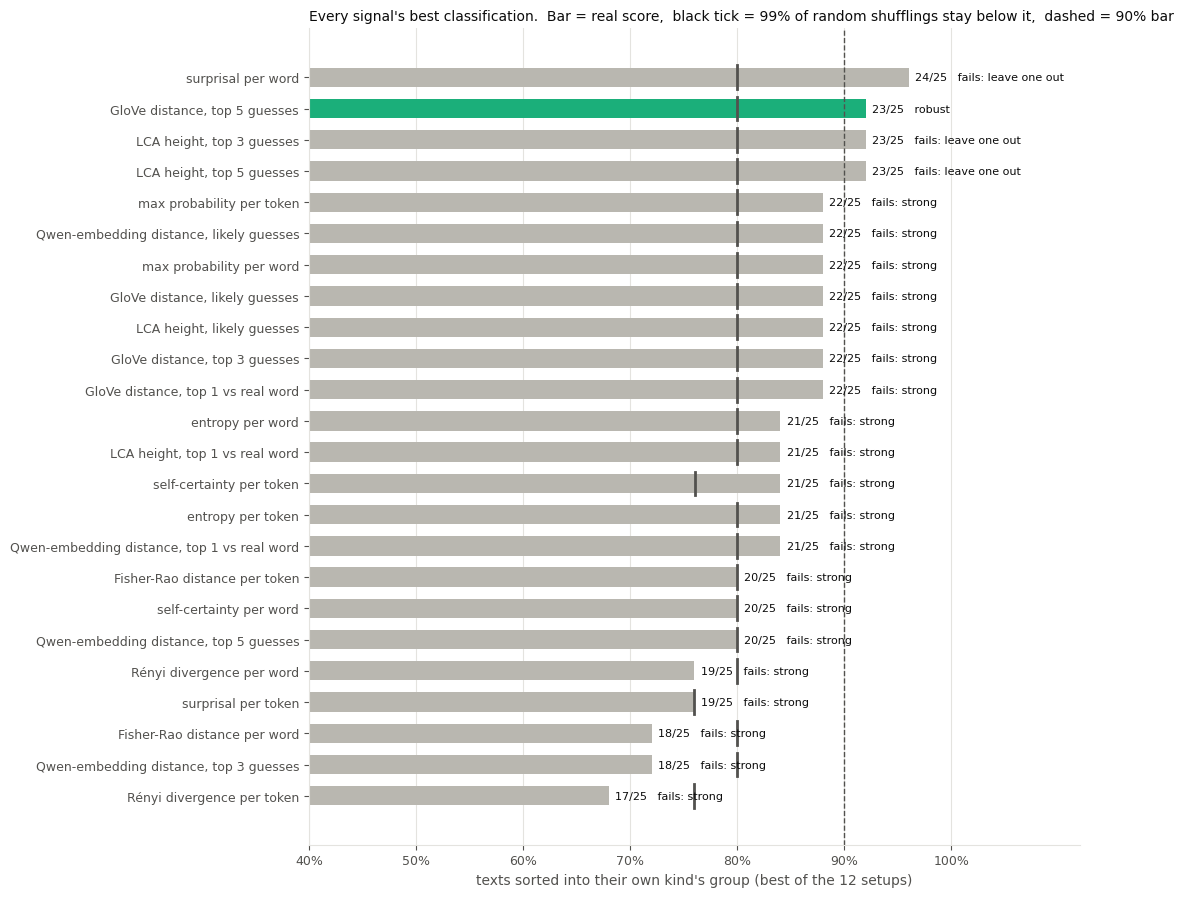

,name,best setup,correct,texts,factual correct,creative correct,chance 99th percentile,chance p,leave-one-out worst,window worst,failed test
12,surprisal per word,"shape only, DTW, k-medoids",24,25,12,12,20.00,0.000,0.750,0.92,leave one out
1,"LCA height, top 3 guesses","raw, DTW, DTW-KMeans",23,25,11,12,20.00,0.000,0.583,0.60,leave one out
6,"GloVe distance, top 5 guesses","raw, DTW, k-medoids",23,25,10,13,20.00,0.000,0.917,0.92,
2,"LCA height, top 5 guesses","raw, DTW, DTW-KMeans",23,25,11,12,20.00,0.000,0.542,0.52,leave one out
5,"GloVe distance, top 3 guesses","raw, DTW, k-medoids",22,25,12,10,20.00,0.000,NaN,NaN,strong
4,"GloVe distance, top 1 vs real word","raw, DTW, DTW-KMeans",22,25,11,11,20.00,0.000,NaN,NaN,strong
7,"GloVe distance, likely guesses","raw, DTW, k-medoids",22,25,9,13,20.00,0.000,NaN,NaN,strong
3,"LCA height, likely guesses","shape only, DTW, k-medoids",22,25,9,13,20.00,0.000,NaN,NaN,strong
13,max probability per word,"raw, Euclidean, k-medoids",22,25,10,12,20.00,0.000,NaN,NaN,strong
11,"Qwen-embedding distance, likely guesses","raw, DTW, k-medoids",22,25,9,13,20.00,0.000,NaN,NaN,strong


In [5]:
save(plot_overview(verdicts), "2_every_signal.png")
plt.show()
verdicts[["name", "best setup", "correct", "texts", "factual correct", "creative correct", "chance 99th percentile",
          "chance p", "leave-one-out worst", "window worst", "failed test"]].sort_values(
    "correct", ascending=False).round(3)

## 5. The curves behind the strongest signals
For every signal that passed the first two tests: each text's whole curve as one row (nothing averaged), and
the group its best setup put the text in.

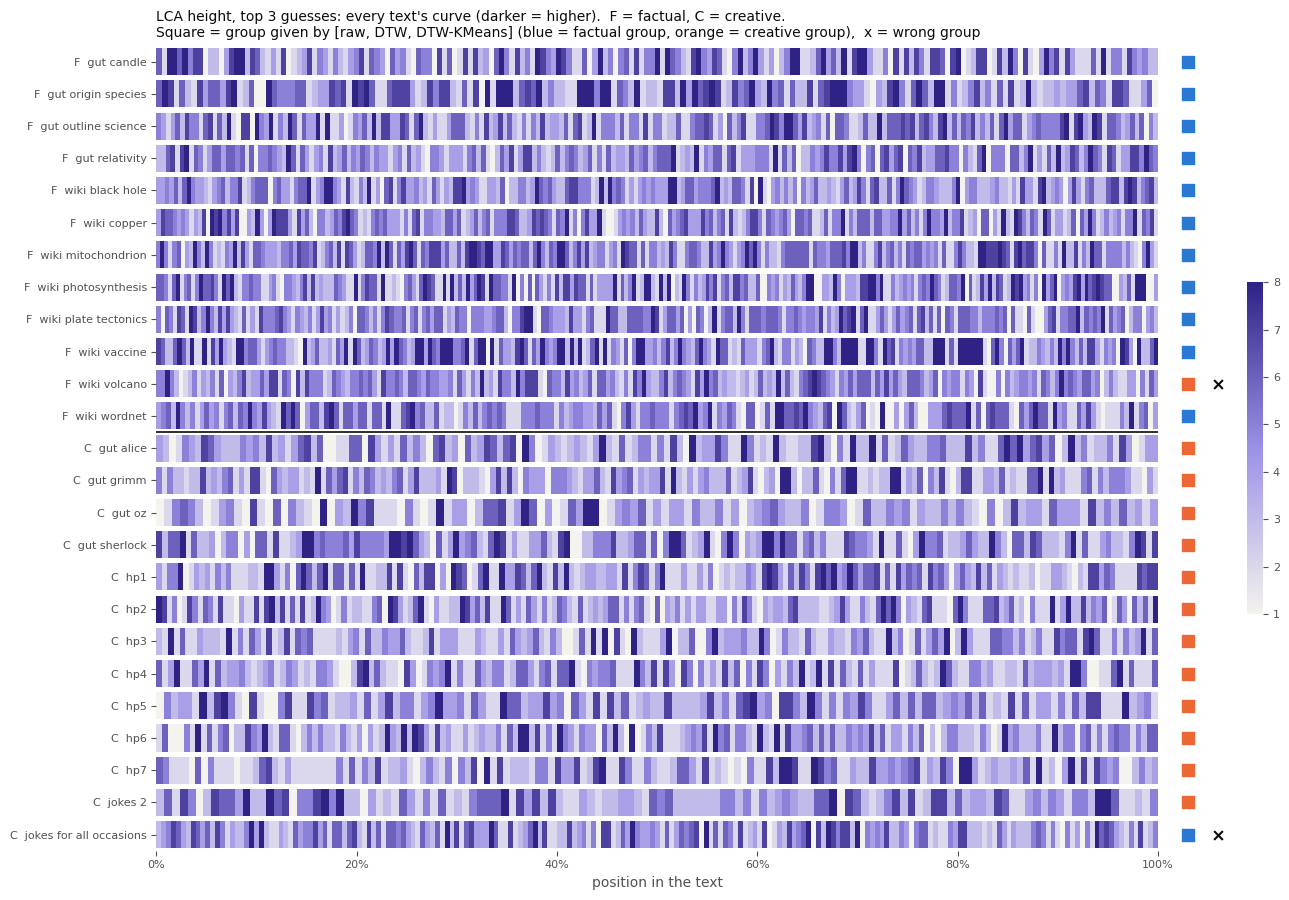

,window,correct,texts,share correct,signal
0,0.05,15,25,0.60,lca_top3
1,0.10,23,25,0.92,lca_top3
2,0.20,23,25,0.92,lca_top3


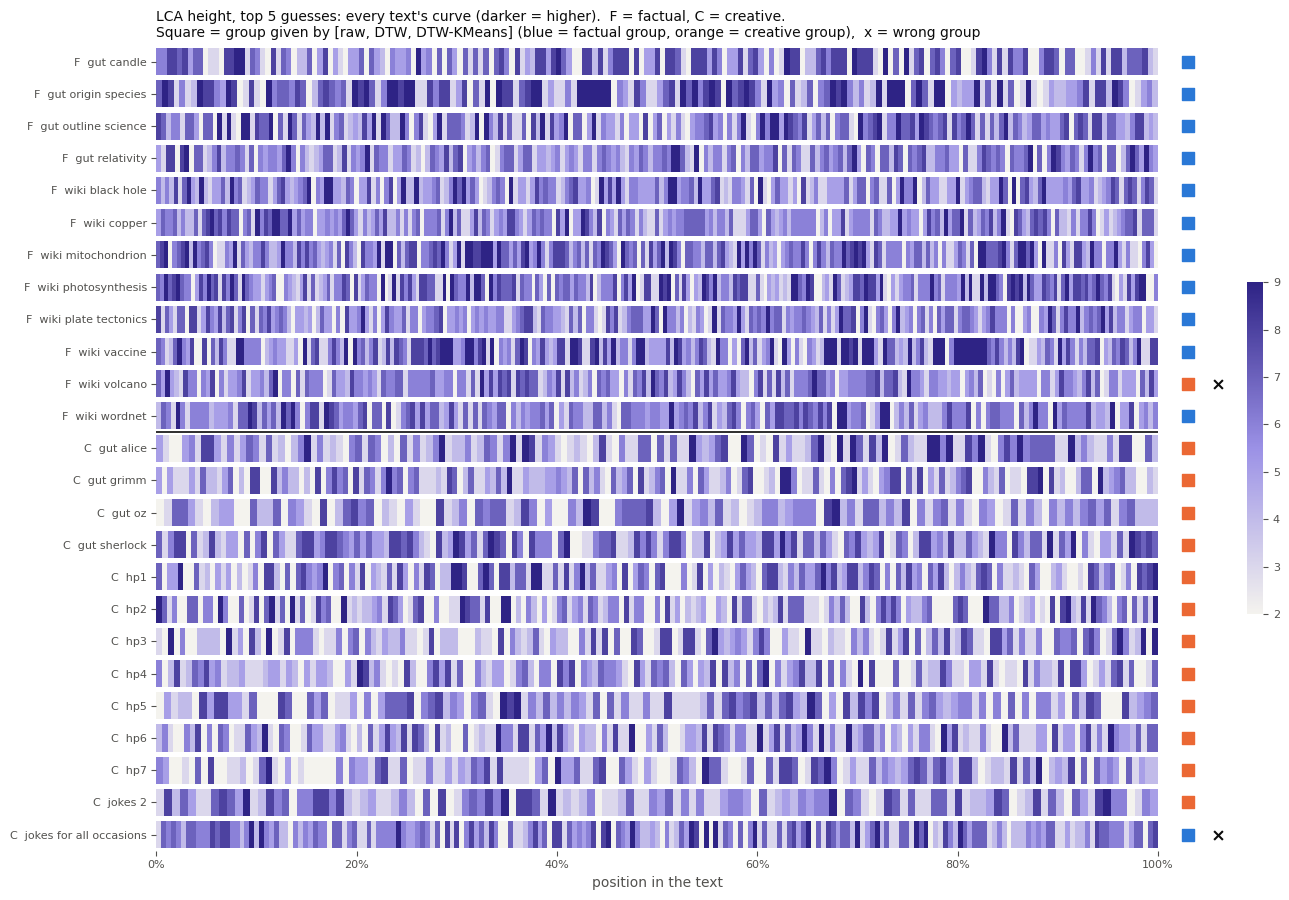

,window,correct,texts,share correct,signal
3,0.05,13,25,0.52,lca_top5
4,0.10,23,25,0.92,lca_top5
5,0.20,13,25,0.52,lca_top5


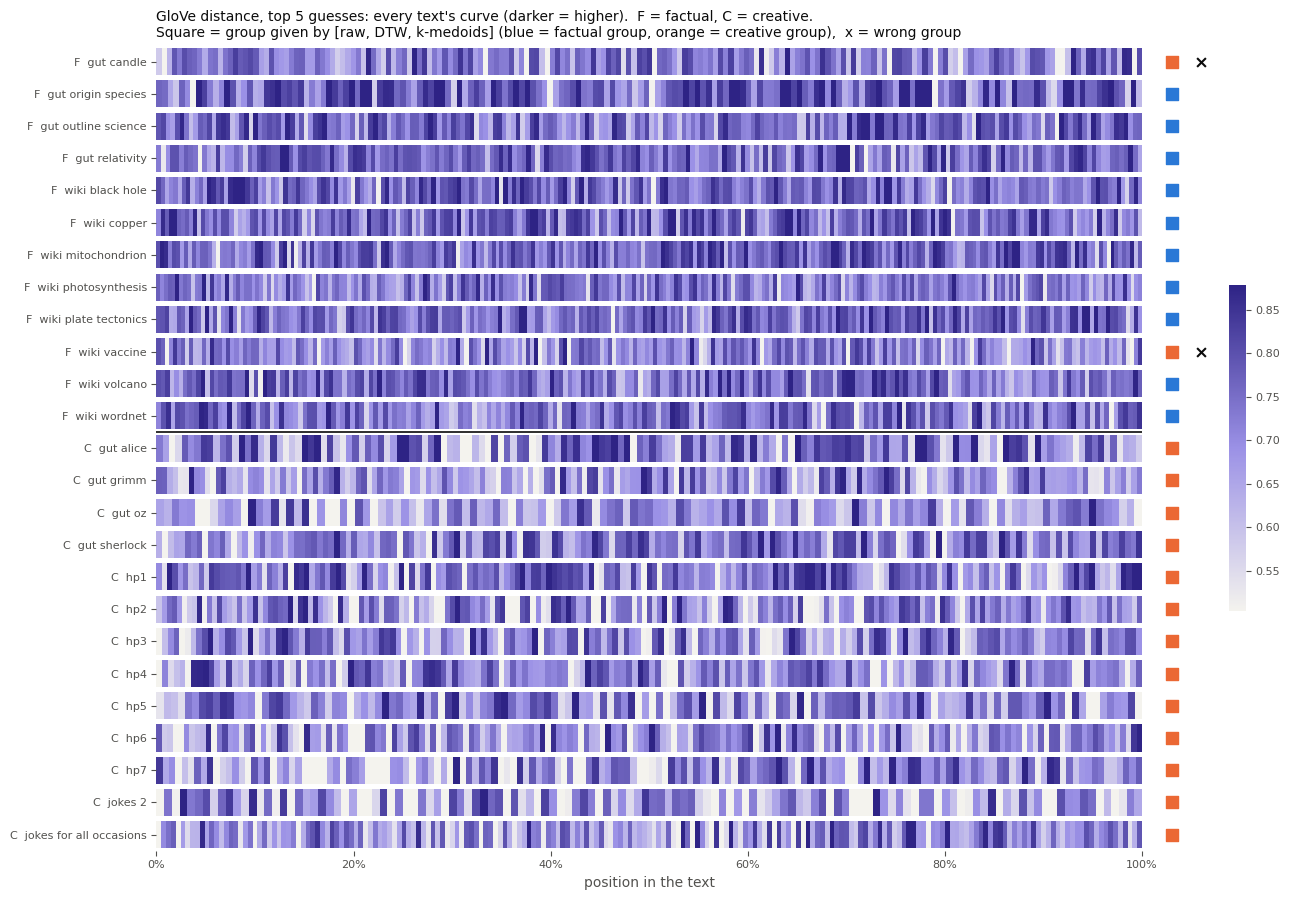

,window,correct,texts,share correct,signal
6,0.05,23,25,0.92,glove_top5
7,0.10,23,25,0.92,glove_top5
8,0.20,23,25,0.92,glove_top5


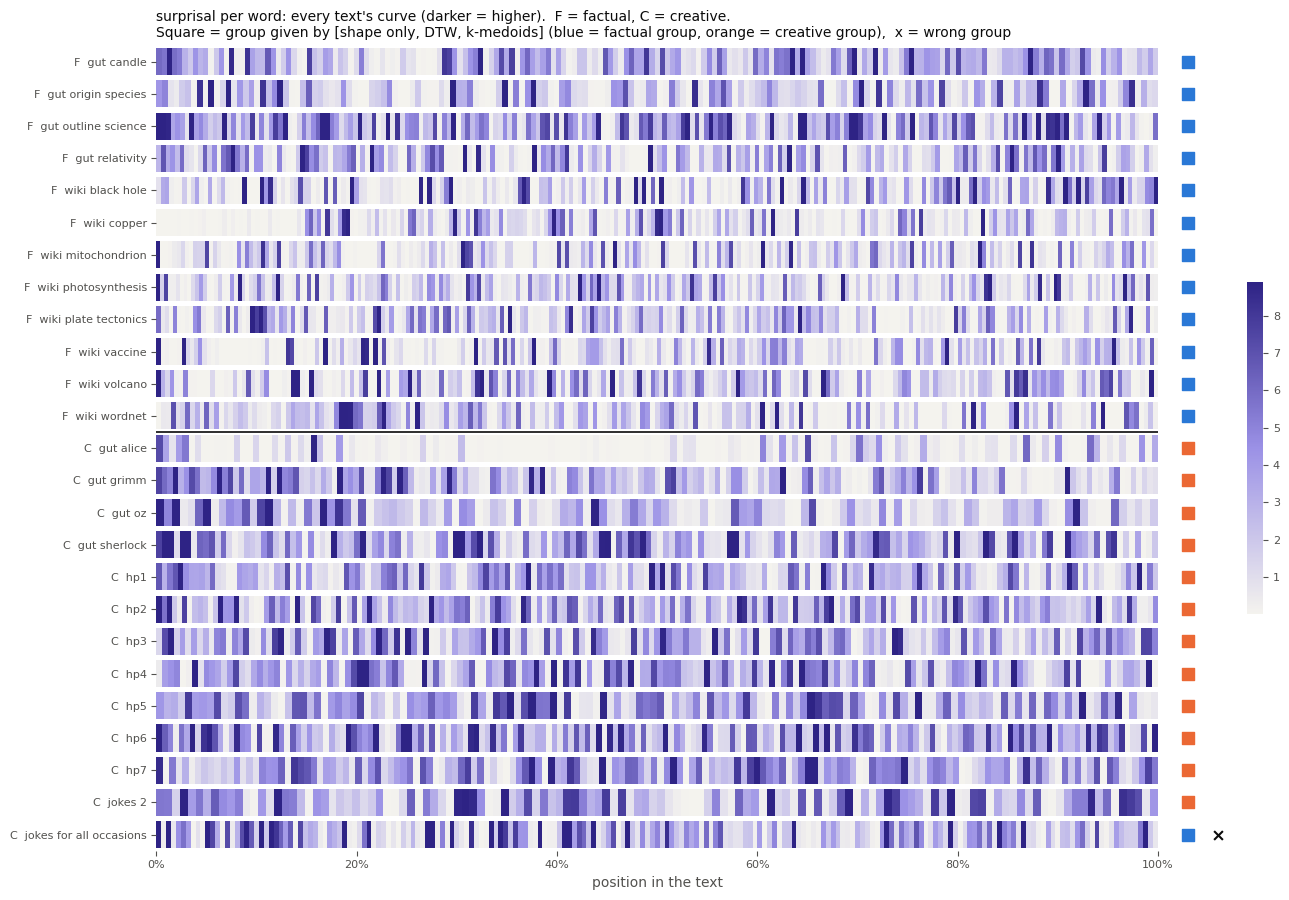

,window,correct,texts,share correct,signal
9,0.05,23,25,0.92,surprisal_per_word
10,0.10,24,25,0.96,surprisal_per_word
11,0.20,23,25,0.92,surprisal_per_word


In [6]:
reached_stability_tests = verdicts[verdicts["leave-one-out worst"].notna()]
for _index, verdict in reached_stability_tests.iterrows():
    signal = None
    for candidate in SIGNALS:
        if candidate.key == verdict["signal"]:
            signal = candidate
    curves = curves_of(signal, names, word_tables, token_tables)
    labels = group(curves, setup_from_name(verdict["best setup"]))
    figure = plot_curves(signal.name, verdict["best setup"], names, kinds, curves, labels)
    save(figure, f"3_curves_{signal.key}.png")
    plt.show()
    display(window_scores[window_scores["signal"] == signal.key].round(3))

## 6. Leave one out: does a single text carry the result?

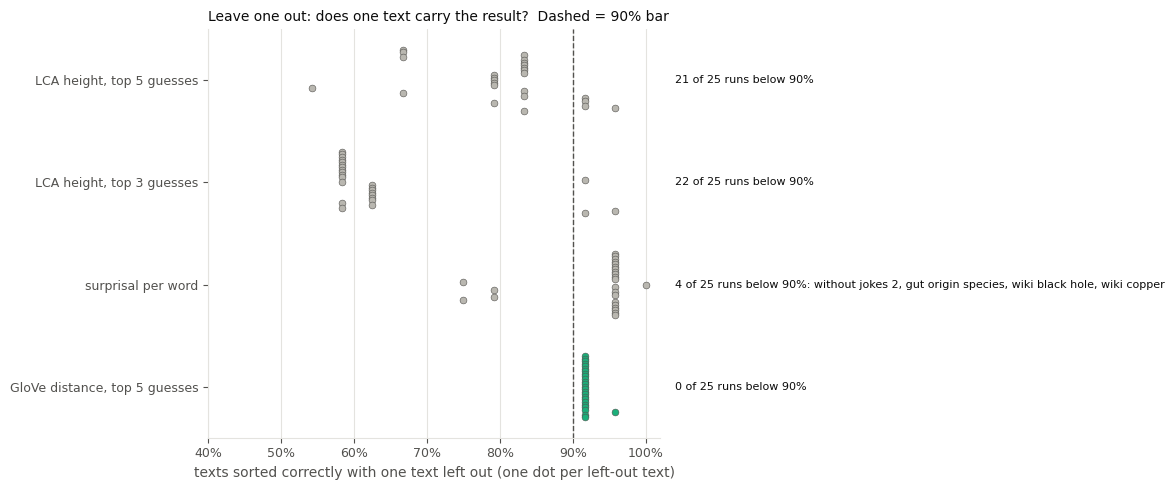

In [7]:
save(plot_leave_one_out(leave_one_out_scores, verdicts), "4_leave_one_out.png")
plt.show()

## 7. Which setups work
Each setup's score for every signal. This shows which ways of comparing curves carry the information.

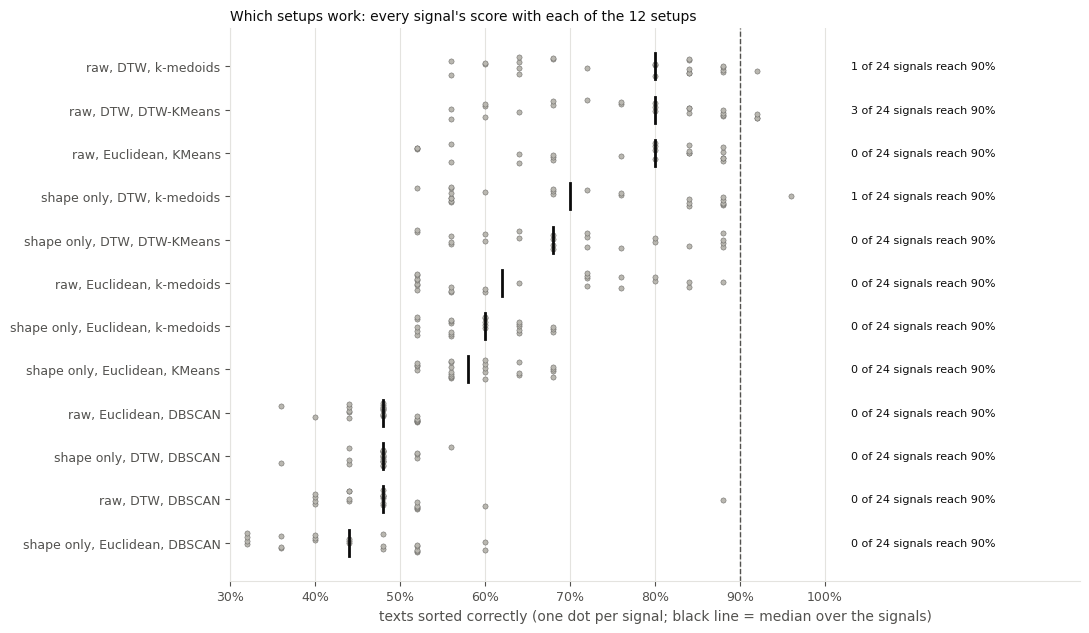

,min,50%,max
setup,,,
"raw, DTW, DTW-KMeans",0.56,0.80,0.92
"raw, DTW, k-medoids",0.56,0.80,0.92
"raw, Euclidean, KMeans",0.52,0.80,0.88
"shape only, DTW, k-medoids",0.52,0.70,0.96
"shape only, DTW, DTW-KMeans",0.52,0.68,0.88
"raw, Euclidean, k-medoids",0.52,0.62,0.88
"shape only, Euclidean, k-medoids",0.52,0.60,0.68
"shape only, Euclidean, KMeans",0.52,0.58,0.68
"raw, Euclidean, DBSCAN",0.16,0.48,0.52


In [8]:
save(plot_setups(setup_scores), "5_setups.png")
plt.show()
setup_scores.groupby("setup")["share correct"].describe()[["min", "50%", "max"]].sort_values(
    "50%", ascending=False).round(3)

## 8. Negative results
Every signal that is not a robust result, with the test it failed first. Why each one fails is explained in
`CONCLUSIONS.md`.

In [9]:
negative = verdicts[~verdicts["robust"]].sort_values("correct", ascending=False)
negative[["name", "failed test", "correct", "texts", "best setup", "chance 99th percentile",
          "leave-one-out worst", "window worst"]].round(3)

,name,failed test,correct,texts,best setup,chance 99th percentile,leave-one-out worst,window worst
12,surprisal per word,leave one out,24,25,"shape only, DTW, k-medoids",20.00,0.750,0.92
2,"LCA height, top 5 guesses",leave one out,23,25,"raw, DTW, DTW-KMeans",20.00,0.542,0.52
1,"LCA height, top 3 guesses",leave one out,23,25,"raw, DTW, DTW-KMeans",20.00,0.583,0.60
5,"GloVe distance, top 3 guesses",strong,22,25,"raw, DTW, k-medoids",20.00,NaN,NaN
4,"GloVe distance, top 1 vs real word",strong,22,25,"raw, DTW, DTW-KMeans",20.00,NaN,NaN
7,"GloVe distance, likely guesses",strong,22,25,"raw, DTW, k-medoids",20.00,NaN,NaN
3,"LCA height, likely guesses",strong,22,25,"shape only, DTW, k-medoids",20.00,NaN,NaN
13,max probability per word,strong,22,25,"raw, Euclidean, k-medoids",20.00,NaN,NaN
11,"Qwen-embedding distance, likely guesses",strong,22,25,"raw, DTW, k-medoids",20.00,NaN,NaN
19,max probability per token,strong,22,25,"raw, Euclidean, KMeans",20.00,NaN,NaN
